# 06 - Final held-out test evaluation

**Run this notebook once.** The test set must not influence any choice.

- Settings come from notebook 05 (chosen on the validation set only).
- Every model is **fitted on the training set only** (no refit on train + validation).
- Positive class = abnormal (`figo_label = 1`). All 103 signal features.
- Academic results only; not a clinical diagnostic claim.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             balanced_accuracy_score, confusion_matrix, roc_curve)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

SEED = 42
TARGET_COLUMN = "figo_label"
GROUP_COLUMN = "patient_id"
FEATURE_PREFIXES = ("F_", "U_", "FU_")

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
RESULTS_DIR = PROJECT_ROOT / "results"
print("Python", sys.version.split()[0], "| scikit-learn", sklearn.__version__)

# Settings chosen on the VALIDATION set in notebook 05
best_params = json.loads((RESULTS_DIR / "best_params.json").read_text())
print("Models with saved settings:", list(best_params.keys()))

Python 3.13.12 | scikit-learn 1.9.1
Models with saved settings: ['Logistic Regression', 'Decision Tree', 'KNN', 'LightGBM', 'XGBoost', 'Random Forest', 'SVM']


## Load train and test (and check patient overlap)

In [2]:
# Load TRAIN and TEST. This is the one and only held-out test evaluation.
train_df = pd.read_csv(PROCESSED_DIR / "train.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test.csv")

# Integrity check: no patient may appear in both train and test
train_patients = set(train_df[GROUP_COLUMN])
test_patients = set(test_df[GROUP_COLUMN])
shared_patients = train_patients.intersection(test_patients)
print("Patients in both train and test:", len(shared_patients))
if len(shared_patients) > 0:
    raise ValueError("Patient overlap between train and test. Stop and investigate.")

feature_cols = []
for col in train_df.columns:
    if col.startswith(FEATURE_PREFIXES):
        feature_cols.append(col)
if len(feature_cols) != 103:
    raise ValueError("Expected 103 features, found " + str(len(feature_cols)))

X_train = train_df[feature_cols].replace([np.inf, -np.inf], np.nan)
y_train = train_df[TARGET_COLUMN].astype(int)
X_test = test_df[feature_cols].replace([np.inf, -np.inf], np.nan)
y_test = test_df[TARGET_COLUMN].astype(int)
print("Train:", X_train.shape, " Test:", X_test.shape, " Test abnormal share: %.3f" % y_test.mean())

Patients in both train and test: 0
Train: (14540, 103)  Test: (3114, 103)  Test abnormal share: 0.538


## Pipeline builder

In [3]:
def make_pipeline(name, params):
    """Same pipeline as notebook 05: imputer (+ scaler for LR, KNN, SVM) + model, fitted on TRAIN only."""
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if name in ("Logistic Regression", "KNN", "SVM"):
        steps.append(("scaler", StandardScaler()))

    if name == "Logistic Regression":
        model = LogisticRegression(max_iter=3000, random_state=SEED, **params)
    elif name == "KNN":
        model = KNeighborsClassifier(**params)
    elif name == "SVM":
        model = SVC(kernel="rbf", random_state=SEED, **params)
    elif name == "Decision Tree":
        model = DecisionTreeClassifier(random_state=SEED, **params)
    elif name == "Random Forest":
        model = RandomForestClassifier(random_state=SEED, n_jobs=-1, **params)
    elif name == "XGBoost":
        model = XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric="logloss", **params)
    else:
        model = LGBMClassifier(random_state=SEED, n_jobs=-1, verbose=-1, **params)

    steps.append(("model", model))
    return Pipeline(steps)

## Fit on train, evaluate on test

In [4]:
rows = []
roc_points = {}

for model_name in best_params:
    params = best_params[model_name]["params"]

    # Fit on the TRAINING set only (no refit on train + validation)
    pipe = make_pipeline(model_name, params)
    pipe.fit(X_train, y_train)

    # Predict the held-out TEST set
    test_pred = pipe.predict(X_test)
    if model_name == "SVM":
        test_score = pipe.decision_function(X_test)
    else:
        test_score = pipe.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(y_test, test_pred).ravel()
    row = {
        "model": model_name,
        "accuracy": accuracy_score(y_test, test_pred),
        "precision": precision_score(y_test, test_pred, pos_label=1),
        "recall": recall_score(y_test, test_pred, pos_label=1),
        "f1": f1_score(y_test, test_pred, pos_label=1),
        "roc_auc": roc_auc_score(y_test, test_score),
        "balanced_accuracy": balanced_accuracy_score(y_test, test_pred),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "validation_f1": best_params[model_name]["val_f1"],
    }
    rows.append(row)

    fpr, tpr, _ = roc_curve(y_test, test_score)
    keep = np.unique(np.linspace(0, len(fpr) - 1, 90).astype(int))
    roc_points[model_name] = {"fpr": [round(float(x), 4) for x in fpr[keep]],
                              "tpr": [round(float(x), 4) for x in tpr[keep]],
                              "auc": round(float(row["roc_auc"]), 4)}
    print(model_name, "| test F1 %.4f | AUC %.4f | validation F1 %.4f" % (row["f1"], row["roc_auc"], row["validation_f1"]))

test_df_results = pd.DataFrame(rows).sort_values("f1", ascending=False)
display(test_df_results.round(4))

Logistic Regression | test F1 0.9775 | AUC 0.9978 | validation F1 0.9799
Decision Tree | test F1 0.8423 | AUC 0.9049 | validation F1 0.8535
KNN | test F1 0.8417 | AUC 0.9364 | validation F1 0.8503
LightGBM | test F1 0.9568 | AUC 0.9924 | validation F1 0.9571
XGBoost | test F1 0.9578 | AUC 0.9924 | validation F1 0.9579
Random Forest | test F1 0.9049 | AUC 0.9618 | validation F1 0.9024
SVM | test F1 0.9710 | AUC 0.9971 | validation F1 0.9723


,model,accuracy,precision,recall,f1,roc_auc,balanced_accuracy,tn,fp,fn,tp,validation_f1
0,Logistic Regression,0.9759,0.9802,0.9749,0.9775,0.9978,0.9760,1407,33,42,1632,0.9799
6,SVM,0.9689,0.9724,0.9695,0.9710,0.9971,0.9688,1394,46,51,1623,0.9723
4,XGBoost,0.9550,0.9671,0.9486,0.9578,0.9924,0.9556,1386,54,86,1588,0.9579
3,LightGBM,0.9538,0.9614,0.9522,0.9568,0.9924,0.9539,1376,64,80,1594,0.9571
5,Random Forest,0.8969,0.8977,0.9122,0.9049,0.9618,0.8957,1266,174,147,1527,0.9024
1,Decision Tree,0.8317,0.8489,0.8357,0.8423,0.9049,0.8314,1191,249,275,1399,0.8535
2,KNN,0.8423,0.9145,0.7796,0.8417,0.9364,0.8474,1318,122,369,1305,0.8503


## Save results and figures

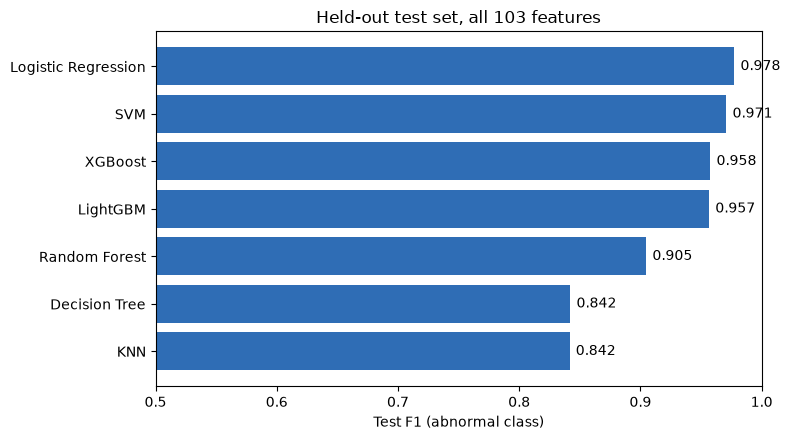

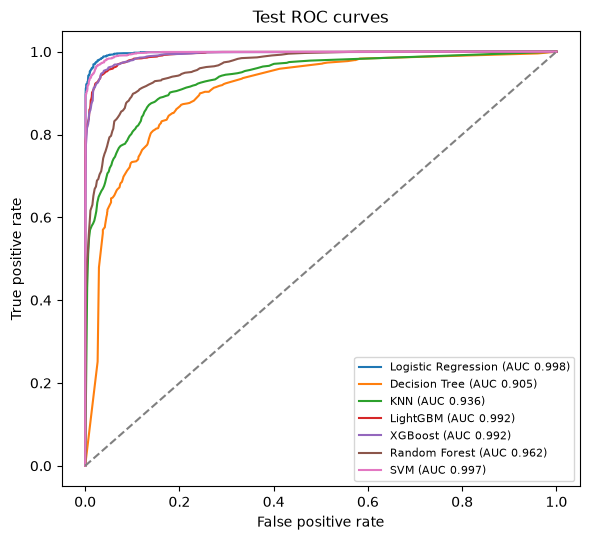

Saved test_metrics.csv, test_roc_curves.json and two figures in c:\Users\Rathishan\Desktop\Desktop\Git\ML_Module\Machine-Learning-Based-Fetal-Well-being-Classification-Using-Cardiotocography-Features\results


In [5]:
# Save the test results
test_df_results.to_csv(RESULTS_DIR / "test_metrics.csv", index=False)
(RESULTS_DIR / "test_roc_curves.json").write_text(json.dumps(roc_points))

# Figure 1: test F1 per model
fig, ax = plt.subplots(figsize=(8, 4.5))
ordered = test_df_results.sort_values("f1")
ax.barh(ordered["model"], ordered["f1"], color="#2f6db5")
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("Test F1 (abnormal class)")
ax.set_title("Held-out test set, all 103 features")
for i, value in enumerate(ordered["f1"]):
    ax.text(value + 0.005, i, "%.3f" % value, va="center")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "test_f1_by_model.png", dpi=200)
plt.show()

# Figure 2: test ROC curves
fig, ax = plt.subplots(figsize=(6, 5.5))
for model_name in roc_points:
    ax.plot(roc_points[model_name]["fpr"], roc_points[model_name]["tpr"],
            label=model_name + " (AUC %.3f)" % roc_points[model_name]["auc"])
ax.plot([0, 1], [0, 1], "--", color="grey")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("Test ROC curves")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "test_roc_curves.png", dpi=200)
plt.show()
print("Saved test_metrics.csv, test_roc_curves.json and two figures in", RESULTS_DIR)